# Lab 27.2: The Reference Audit

*Explainable AI in Practice*, Chapter 27. Run-only notebook: run the cells from top to bottom. One optional edit is marked in Part G.

This notebook re-performs the evidence of the chapter's case study: an explanation audit of a credit model on the public German Credit (Statlog) data (Hofmann, 1994; UCI Machine Learning Repository, CC BY 4.0, DOI 10.24432/C5NC77; downloaded from OpenML as `credit-g`). The data is old and is used to learn methods, not to judge real lending. The model is the same gradient-boosted model as in Chapter 23.

Each part is one audit test. After each part, write one line in your finding register: the criterion, the condition you observed, and whether it is a finding.

In [1]:
import itertools, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
import sklearn, shap
warnings.filterwarnings("ignore")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| shap", shap.__version__)
T0 = time.time()

numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.7.2 | shap 0.49.1


## Part A. Scope: the system under audit

The reference system: a gradient-boosted classifier that predicts a bad credit outcome; an applicant is declined when the predicted risk is above 0.5. Categorical attributes are integer codes, as in Chapter 23.

In [2]:
d = fetch_openml("credit-g", version=1, as_frame=True).frame
y = (d.pop("class") == "bad").astype(int)
cats = [c for c in d.columns if str(d[c].dtype) == "category"]
X = d.copy()
for c in cats:
    X[c] = X[c].cat.codes
X = X.astype(float); cols = list(X.columns); num = [c for c in cols if c not in cats]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

def gbm_fit(Xa, ya, seed=0):
    return GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                      random_state=seed).fit(Xa, ya)
gbm = gbm_fit(Xtr, ytr)
p = gbm.predict_proba(Xte)[:, 1]
dec = np.where(p > 0.5)[0]
A = Xte.iloc[dec]
print(f"{len(X)} applicants, {len(Xte)} in the test set; test AUC {roc_auc_score(yte, p):.3f}; declined {len(dec)}")

1000 applicants, 300 in the test set; test AUC 0.778; declined 57


**Checkpoint 1:** test AUC 0.778; 57 of 300 test applicants declined.

## Part B. Choose: is the black box needed? (Chapter 5)

Criterion: the dossier claims that a glass box would lose accuracy. Re-perform the comparison with a regularized logistic regression on one-hot categories, and put a bootstrap interval on the difference.

In [3]:
def lr_pipe(C):
    return make_pipeline(ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), [cols.index(c) for c in cats]),
                                            ("n", StandardScaler(), [cols.index(c) for c in num])]),
                         LogisticRegression(C=C, max_iter=3000))
plr = lr_pipe(0.3).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
rng = np.random.default_rng(0); yv = yte.values; aucs, diffs = [], []
for b in range(2000):
    i = rng.integers(0, len(yv), len(yv))
    a1, a2 = roc_auc_score(yv[i], p[i]), roc_auc_score(yv[i], plr[i])
    aucs.append(a1); diffs.append(a1 - a2)
print(f"GBM AUC {roc_auc_score(yte, p):.3f}, 95% interval {np.percentile(aucs, 2.5):.3f} to {np.percentile(aucs, 97.5):.3f}")
print(f"Logistic regression AUC {roc_auc_score(yte, plr):.3f}")
print(f"GBM minus LR: {roc_auc_score(yte, p) - roc_auc_score(yte, plr):+.3f}, 95% interval {np.percentile(diffs, 2.5):+.3f} to {np.percentile(diffs, 97.5):+.3f}")

GBM AUC 0.778, 95% interval 0.722 to 0.830
Logistic regression AUC 0.811
GBM minus LR: -0.032, 95% interval -0.073 to +0.008


**Checkpoint 2:** GBM 0.778 (interval 0.722 to 0.830); logistic regression 0.811; difference -0.032 with an interval from -0.073 to +0.008. The test set cannot show that the black box is more accurate.

## Part C. Test, faithful: do the stated reasons drive the score? (Chapters 8 and 20)

Reason codes are the three features with the largest positive interventional SHAP values (TreeSHAP, background of 100 training rows). Deletion test: replace features by background values (averaged over the 100 background rows) in the order of the reasons, and compare with random orders.

mean risk, reasons removed first: [0.668 0.458 0.349 0.293 0.252 0.233 0.217]
mean risk, random order:          [0.668 0.639 0.61  0.575 0.557 0.524 0.497]
gap after 3 features: 0.282, 95% interval 0.259 to 0.307
declined applicants whose risk falls below 0.5 once their 3 reasons are removed: 96.5%


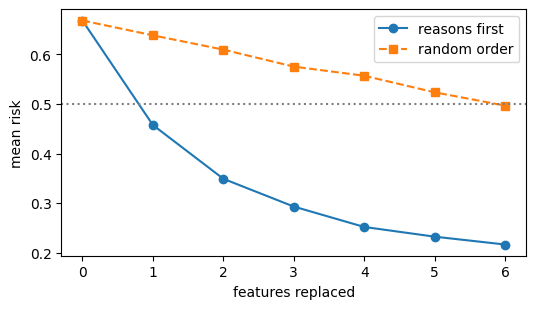

In [4]:
bg1, bg2 = Xtr.sample(100, random_state=0), Xtr.sample(100, random_state=1)
sv = lambda m, bg: shap.TreeExplainer(m, data=bg).shap_values(A)
S1 = sv(gbm, bg1)
bgv = bg1.values
def risk_after(x, feats, model=gbm):
    Z = np.repeat(x[None, :], len(bgv), 0)
    if feats:
        Z[:, feats] = bgv[:, feats]
    return model.predict_proba(pd.DataFrame(Z, columns=cols))[:, 1].mean()
K = 6; cs, cr = np.zeros((len(A), K + 1)), np.zeros((len(A), K + 1))
for i, (x, s) in enumerate(zip(A.values, S1)):
    order = list(np.argsort(-s))
    cs[i] = [risk_after(x, order[:k]) for k in range(K + 1)]
    for r in range(20):
        o = list(np.random.default_rng(100 + r).permutation(len(cols)))
        cr[i] += np.array([risk_after(x, o[:k]) for k in range(K + 1)]) / 20
g = cr - cs
boots = np.array([g[np.random.default_rng(b).integers(0, len(g), len(g))].mean(0) for b in range(2000)])
print("mean risk, reasons removed first:", cs.mean(0).round(3))
print("mean risk, random order:         ", cr.mean(0).round(3))
print(f"gap after 3 features: {g[:, 3].mean():.3f}, 95% interval {np.percentile(boots[:, 3], 2.5):.3f} to {np.percentile(boots[:, 3], 97.5):.3f}")
print(f"declined applicants whose risk falls below 0.5 once their 3 reasons are removed: {(cs[:, 3] < 0.5).mean():.1%}")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(K + 1), cs.mean(0), "-o", label="reasons first"); ax.plot(range(K + 1), cr.mean(0), "--s", label="random order")
ax.axhline(0.5, ls=":", c="gray"); ax.set_xlabel("features replaced"); ax.set_ylabel("mean risk"); ax.legend(); plt.show()

**Checkpoint 3:** after three features, 0.293 (reasons first) against 0.575 (random); gap 0.282, interval 0.259 to 0.307; 96.5 percent fall below 0.5.

## Part D. Test, stable: same reasons under a second background and after retraining? (Chapters 8 and 25)

In [5]:
top3 = lambda s: set(np.argsort(-s)[:3])
jac = lambda a, b: len(a & b) / len(a | b)
S2 = sv(gbm, bg2)
j_bg = np.array([jac(top3(a), top3(b)) for a, b in zip(S1, S2)])
jr, still = [], []
for s in range(1, 6):
    idx = np.random.default_rng(s).integers(0, len(Xtr), len(Xtr))
    m = gbm_fit(Xtr.iloc[idx], ytr.iloc[idx])
    jr.append([jac(top3(a), top3(b)) for a, b in zip(S1, sv(m, bg1))])
    still.append((m.predict_proba(A)[:, 1] > 0.5).mean())
j_rt = np.mean(jr, 0)
print(f"second background: mean top-3 agreement {j_bg.mean():.3f}; identical top 3 for {np.mean(j_bg == 1):.1%}")
print(f"five retrains: mean top-3 agreement {j_rt.mean():.3f}; agreement below 0.5 for {np.mean(j_rt < 0.5):.1%}")
print("share of the 57 still declined after each retrain:", np.round(still, 3))

second background: mean top-3 agreement 0.930; identical top 3 for 86.0%
five retrains: mean top-3 agreement 0.578; agreement below 0.5 for 29.8%
share of the 57 still declined after each retrain: [0.684 0.544 0.491 0.825 0.702]


**Checkpoint 4:** background change 0.930 (86.0 percent identical); retrains 0.578 (29.8 percent below 0.5); still declined 0.684, 0.544, 0.491, 0.825, 0.702.

## Part E. Test, useful for the applicant: is the recourse actionable? (Chapter 9)

For each declined applicant, find the cheapest change of at most two features that brings the risk below 0.5. Cost: one unit per changed category, or the change in standard deviations for a number. The naive generator may change anything in any direction; the justified action set allows only shorter duration, a smaller amount, a lower installment rate, or adding a co-applicant or guarantor.

In [6]:
IMM = ["age", "personal_status", "foreign_worker"]
ACT = {"duration": "down", "credit_amount": "down", "installment_commitment": "down", "other_parties": "guar"}
sd = Xtr.std()
G = {c: (np.unique(Xtr[c].values) if c in cats else np.unique(np.quantile(Xtr[c].values, np.linspace(0, 1, 11)).round())) for c in cols}
cost = lambda c, old, new: 1.0 if c in cats else abs(new - old) / sd[c]
def allowed_dir(c, old, new):
    return new < old if ACT[c] == "down" else new in (0.0, 1.0)
def allowed_just(c, old, new):
    return c in ACT and new != old and allowed_dir(c, old, new)
def best_flip(x, allowed):
    singles = [(c, v) for c in cols for v in G[c] if allowed(c, x[cols.index(c)], v)]
    cands = [(a,) for a in singles] + [(a, b) for a, b in itertools.combinations(singles, 2) if a[0] != b[0]]
    Z = np.repeat(x[None, :], len(cands), 0)
    for r, ch in enumerate(cands):
        for c, v in ch:
            Z[r, cols.index(c)] = v
    ok = np.where(gbm.predict_proba(pd.DataFrame(Z, columns=cols))[:, 1] < 0.5)[0]
    if len(ok) == 0:
        return None
    costs = [sum(cost(c, x[cols.index(c)], v) for c, v in cands[r]) for r in ok]
    return [(c, x[cols.index(c)], v) for c, v in cands[ok[int(np.argmin(costs))]]]
naive = [best_flip(x, lambda c, o, n: n != o) for x in A.values]
just = [best_flip(x, allowed_just) for x in A.values]
def kinds(recs):
    k = Counter()
    for r in recs:
        if r is None: k["no recourse"] += 1
        elif any(c in IMM for c, o, v in r): k["uses an immutable attribute"] += 1
        elif all(c in ACT and allowed_dir(c, o, v) for c, o, v in r): k["actionable only"] += 1
        else: k["slow feature or wrong direction"] += 1
    return dict(k)
print("naive:    ", kinds(naive))
print("justified:", kinds(just))
print("naive suggestions involving age:", sum(1 for r in naive if r for c, o, v in r if c == "age"),
      "| of which 'be older':", sum(1 for r in naive if r for c, o, v in r if c == "age" and v > o))
print("justified features used:", Counter(c for r in just if r for c, o, v in r).most_common())

naive:     {'uses an immutable attribute': 28, 'actionable only': 8, 'slow feature or wrong direction': 21}
justified: {'actionable only': 56, 'no recourse': 1}
naive suggestions involving age: 28 | of which 'be older': 19
justified features used: [('credit_amount', 31), ('duration', 28), ('installment_commitment', 7), ('other_parties', 3)]


**Checkpoint 5:** naive: 28 use an immutable attribute (all of them age; 19 ask the applicant to be older), 21 use a slow feature or move a loan term the wrong way, 8 are actionable. Justified: 56 actionable, 1 without recourse; amount 31 times, duration 28, installment rate 7, guarantor or co-applicant 3.

## Part F. Limits: how many equally good models tell a different story? (Breiman, 2001; Marx et al., 2020)

Fit 59 models (gradient boosting, random forests and logistic regression with different settings). The near-equal set holds those whose 5-fold cross-validated AUC on the training data is within 0.01 of the reference model's. Each declines its 57 riskiest test applicants. This part takes about a minute.

In [7]:
zoo = []
for ne, dp, lrn, ss, s in itertools.product([100, 200, 400], [2, 3], [0.05, 0.1], [0.7, 1.0], [0, 1]):
    if not (ss == 1.0 and s == 1):
        zoo.append(GradientBoostingClassifier(n_estimators=ne, max_depth=dp, learning_rate=lrn, subsample=ss, random_state=s))
for mf, ml, s in itertools.product([0.3, 0.5, "sqrt"], [1, 5], [0, 1, 2]):
    zoo.append(RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=ml, random_state=s, n_jobs=-1))
zoo += [lr_pipe(C) for C in [0.03, 0.1, 0.3, 1.0, 3.0]]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
cvs = np.array([cross_val_score(m, Xtr, ytr, cv=cv, scoring="roc_auc").mean() for m in zoo])
ref = [i for i, m in enumerate(zoo) if isinstance(m, GradientBoostingClassifier) and m.n_estimators == 200
       and m.max_depth == 3 and m.learning_rate == 0.05 and m.subsample == 1.0][0]
EPS = 0.01   # Part G: try 0.005 or 0.02
keep = [i for i in range(len(zoo)) if cvs[i] >= cvs[ref] - EPS]
D, tops = [], []
for i in keep:
    m = zoo[i].fit(Xtr, ytr); pp = m.predict_proba(Xte)[:, 1]
    dd = np.zeros(len(pp), bool); dd[np.argsort(-pp)[:len(dec)]] = True; D.append(dd)
    pi = permutation_importance(m, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=0)
    tops.append(tuple(cols[j] for j in np.argsort(-pi.importances_mean)[:3]))
D = np.array(D); h0 = np.zeros(len(p), bool); h0[np.argsort(-p)[:len(dec)]] = True
print(f"{len(zoo)} models; reference CV AUC {cvs[ref]:.3f}; best {cvs.max():.3f}; {len(keep)} in the near-equal set")
print(f"ambiguity {(D != h0).any(0).mean():.3f}; discrepancy {(D != h0).mean(1).max():.3f}")
print(f"declined by every model {D.all(0).sum()}, by at least one {D.any(0).sum()}")
print("top-3 permutation importance sets:", Counter(tops).most_common())

59 models; reference CV AUC 0.779; best 0.781; 17 in the near-equal set
ambiguity 0.243; discrepancy 0.153
declined by every model 20, by at least one 93
top-3 permutation importance sets: [(('checking_status', 'duration', 'credit_history'), 10), (('checking_status', 'duration', 'credit_amount'), 3), (('checking_status', 'duration', 'savings_status'), 2), (('checking_status', 'credit_amount', 'purpose'), 1), (('checking_status', 'credit_amount', 'credit_history'), 1)]


**Checkpoint 6:** 59 models; reference CV AUC 0.779, best 0.781; 17 in the set; ambiguity 0.243, discrepancy 0.153; 20 declined by every model, 93 by at least one; checking account is in every top 3, and 10 of 17 share the same top 3.

## Part G. Optional edit

Change `EPS` in Part F to 0.005 or 0.02 and rerun Part F only. Write one sentence on how the size of the near-equal set changes the ambiguity, and what that means for how an auditor should choose the tolerance (Marx et al. recommend setting it from the uncertainty of out-of-sample performance).

In [8]:
print(f"total run time {time.time() - T0:.0f} seconds")

total run time 84 seconds


## Questions

1. Which of Parts B to F produced a finding, and how severe is each by the chapter's scale?
2. Part C passed and Part D partly failed. Can a reason be faithful to today's model and still be the wrong reason to send? Explain.
3. In Part E, why is "borrow less" actionable but not necessarily useful to the applicant? What would you check before sending it?
4. Part F shows a mostly shared global story and unstable individual decisions. Which audiences care about which, and what does that mean for the opinion?
5. Write the opinion for three uses: developer debugging, reason codes in decline letters, and recourse statements.